# Prophet Toko XYZ: Model Peramalan Penjualan (Versi Final)

**Alur penelitian**

1. Data: muat, periksa, lalu bagi menjadi data latih (2024–2025) dan data uji (Jan–Jun 2026)
2. Analisis pola data dan pola di sekitar Idul Fitri/Idul Adha menggunakan data latih
3. Model awal: Prophet dengan holiday aktif dan parameter bawaan
4. Evaluasi model awal menggunakan time-series cross-validation (horizon 30 hari, period 14 hari)
5. Tuning: kombinasi `changepoint_prior_scale`, `seasonality_prior_scale`, `seasonality_mode`, dan `holidays_prior_scale`
6. Pilih kombinasi dengan MAE cross-validation terendah pada masing-masing produk
7. Retrain model terpilih menggunakan seluruh data latih 2024–2025
8. Uji final pada data 2026 Jan–Jun yang tidak digunakan selama tuning
9. Evaluasi tambahan pada hari dengan penjualan aktual > 0 untuk melihat pengaruh hari bernilai nol
10. Hitung reorder point (ROP) dan safety stock (SS) dari error prediksi (lead time 3 hari)
11. Simpan hasil dan konfigurasi (termasuk tabel ROP dan SS) ke `model_config.json` untuk digunakan layanan prediksi aplikasi

**Rumus model Prophet**

`y(t) = g(t) + s(t) + h(t) + ε(t)`

| Simbol | Nama | Arti sederhana |
|---|---|---|
| y(t) | penjualan pada hari ke-t | yang ingin diprediksi |
| g(t) | trend | arah naik/turun jangka panjang |
| s(t) | seasonality | pola berulang seperti mingguan dan tahunan |
| h(t) | holiday effect | dampak Idul Fitri dan Idul Adha |
| ε(t) | error / galat | bagian yang tidak dijelaskan model |


## 1. Setup

In [1]:
# Jika Prophet belum terpasang di Colab, hapus tanda '#':
# !pip install -q prophet

import os, json, time, logging, warnings
from IPython.display import display
from itertools import product as iter_product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet
from prophet.diagnostics import cross_validation

logging.getLogger('prophet').setLevel(logging.WARNING)
logging.getLogger('cmdstanpy').setLevel(logging.WARNING)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

## 2. Data

In [2]:
CSV_PATH = 'historical_sales.csv'

# Jika file belum ada di Colab, hapus tanda '#' lalu pilih file CSV:
# from google.colab import files; files.upload()

df = pd.read_csv(CSV_PATH, parse_dates=['sale_date'])
df = df.sort_values(['product_id', 'sale_date']).reset_index(drop=True)
print('Jumlah baris:', len(df), '| Rentang:', df['sale_date'].min().date(), 's/d', df['sale_date'].max().date())
df.head()

Jumlah baris: 4560 | Rentang: 2024-01-01 s/d 2026-06-30


,id,product_id,sale_date,quantity_sold,price_sold,is_filled,imported_at
0,3959,13,2024-01-01,7000.0,0,0,2026-10-07 17:51:47
1,3960,13,2024-01-02,0.0,0,1,2026-10-07 17:51:47
2,3961,13,2024-01-03,10000.0,0,0,2026-10-07 17:51:47
3,3962,13,2024-01-04,0.0,0,1,2026-10-07 17:51:47
4,3963,13,2024-01-05,9000.0,0,0,2026-10-07 17:51:47


In [40]:
PRODUCTS = {13: 'Beras', 129: 'Kopi Hitam', 158: 'Mie Goreng', 259: 'Telur', 292: 'Yupi 500'}
PRODUCT_IDS = list(PRODUCTS.keys())

TRAIN_START, TRAIN_END = '2024-01-01', '2025-12-31'
TEST_START,  TEST_END  = '2026-01-01', '2026-06-30'

train_df = df[(df['sale_date'] >= TRAIN_START) & (df['sale_date'] <= TRAIN_END)].copy()
test_df  = df[(df['sale_date'] >= TEST_START)  & (df['sale_date'] <= TEST_END)].copy()
assert train_df['sale_date'].max() < test_df['sale_date'].min(), 'Data latih dan uji tumpang tindih!'

print("Data Latih (Training)")
display(train_df.drop(columns=['imported_at']).head())
print("\nData Uji (Testing)")
display(test_df.drop(columns=['imported_at']).head())

# Pemeriksaan: tanggal ganda, tanggal hilang, nilai negatif, dan jumlah hari bernilai nol
print("\n")
print("Ringkasan Hasil Pemeriksaan Kualitas Data:")
cek = []
for pid, g in df.groupby('product_id'):
    penuh = pd.date_range(g['sale_date'].min(), g['sale_date'].max())
    cek.append({'produk': PRODUCTS.get(pid, pid), 'baris': len(g),
                'tanggal_ganda': int(g['sale_date'].duplicated().sum()),
                'tanggal_hilang': len(penuh.difference(g['sale_date'])),
                'nilai_negatif': int((g['quantity_sold'] < 0).sum()),
                'hari_nol': int((g['quantity_sold'] == 0).sum())})
display(pd.DataFrame(cek))

Data Latih (Training)


,id,product_id,sale_date,quantity_sold,price_sold,is_filled
0,3959,13,2024-01-01,7000.0,0,0
1,3960,13,2024-01-02,0.0,0,1
2,3961,13,2024-01-03,10000.0,0,0
3,3962,13,2024-01-04,0.0,0,1
4,3963,13,2024-01-05,9000.0,0,0



Data Uji (Testing)


,id,product_id,sale_date,quantity_sold,price_sold,is_filled
731,4690,13,2026-01-01,0.0,0,1
732,4691,13,2026-01-02,45000.0,0,0
733,4692,13,2026-01-03,49000.0,0,0
734,4693,13,2026-01-04,31000.0,0,0
735,4694,13,2026-01-05,10000.0,0,0




Ringkasan Hasil Pemeriksaan Kualitas Data:


,produk,baris,tanggal_ganda,tanggal_hilang,nilai_negatif,hari_nol
0,Beras,912,0,0,0,369
1,Kopi Hitam,912,0,0,0,366
2,Mie Goreng,912,0,0,0,322
3,Telur,912,0,0,0,255
4,Yupi 500,912,0,0,0,430


### Karakteristik data

Tiga hal yang ditampilkan: (1) tabel ringkasan per produk per tahun, (2) grafik penjualan harian dengan batas data latih dan data uji, (3) persentase hari bernilai nol per bulan. Ketiganya menjelaskan mengapa data ini sulit diprediksi: banyak hari nol, level penjualan berubah antar tahun, dan pola nol berbeda antar periode. Tahun 2026 hanya mencakup Januari–Juni.

In [4]:
tmp = df.assign(tahun=df['sale_date'].dt.year, produk=df['product_id'].map(PRODUCTS))
ringkas_data = (tmp.groupby(['produk', 'tahun'])['quantity_sold']
                   .agg(hari='size',
                        hari_nol_pct=lambda s: (s == 0).mean() * 100,
                        rata2_per_hari='mean',
                        median_hari_terjual=lambda s: s[s > 0].median(),
                        maks='max')
                   .round(1))
ringkas_data

hari  hari_nol_pct  rata2_per_hari  median_hari_terjual     maks
produk     tahun                                                                  
Beras      2024    366          75.4          3337.4              11000.0  40000.0
           2025    365          11.2         20126.0              21000.0  90000.0
           2026    181          28.7         21160.2              30000.0  70000.0
Kopi Hitam 2024    366          63.1            19.5                 45.0    147.0
           2025    365          11.8            65.3                 77.5    161.0
           2026    181          50.8            52.9                108.0    216.0
Mie Goreng 2024    366          60.7            22.7                 51.0    160.0
           2025    365          11.2            72.3                 86.5    185.0
           2026    181          32.6            78.7                112.0    229.0
Telur      2024    366          42.1          5862.0               9000.0  36000.0
           2025    365           9.3         12404.8              12000.0  48000.0
           2026    181          37.0         13551.1              20000.0  55000.0
Yupi 500   2024    366          64.2            22.1                 56.0    250.0
           2025    365          24.1            67.1                 90.0    213.0
           2026    181          59.1            53.0                130.5    241.0

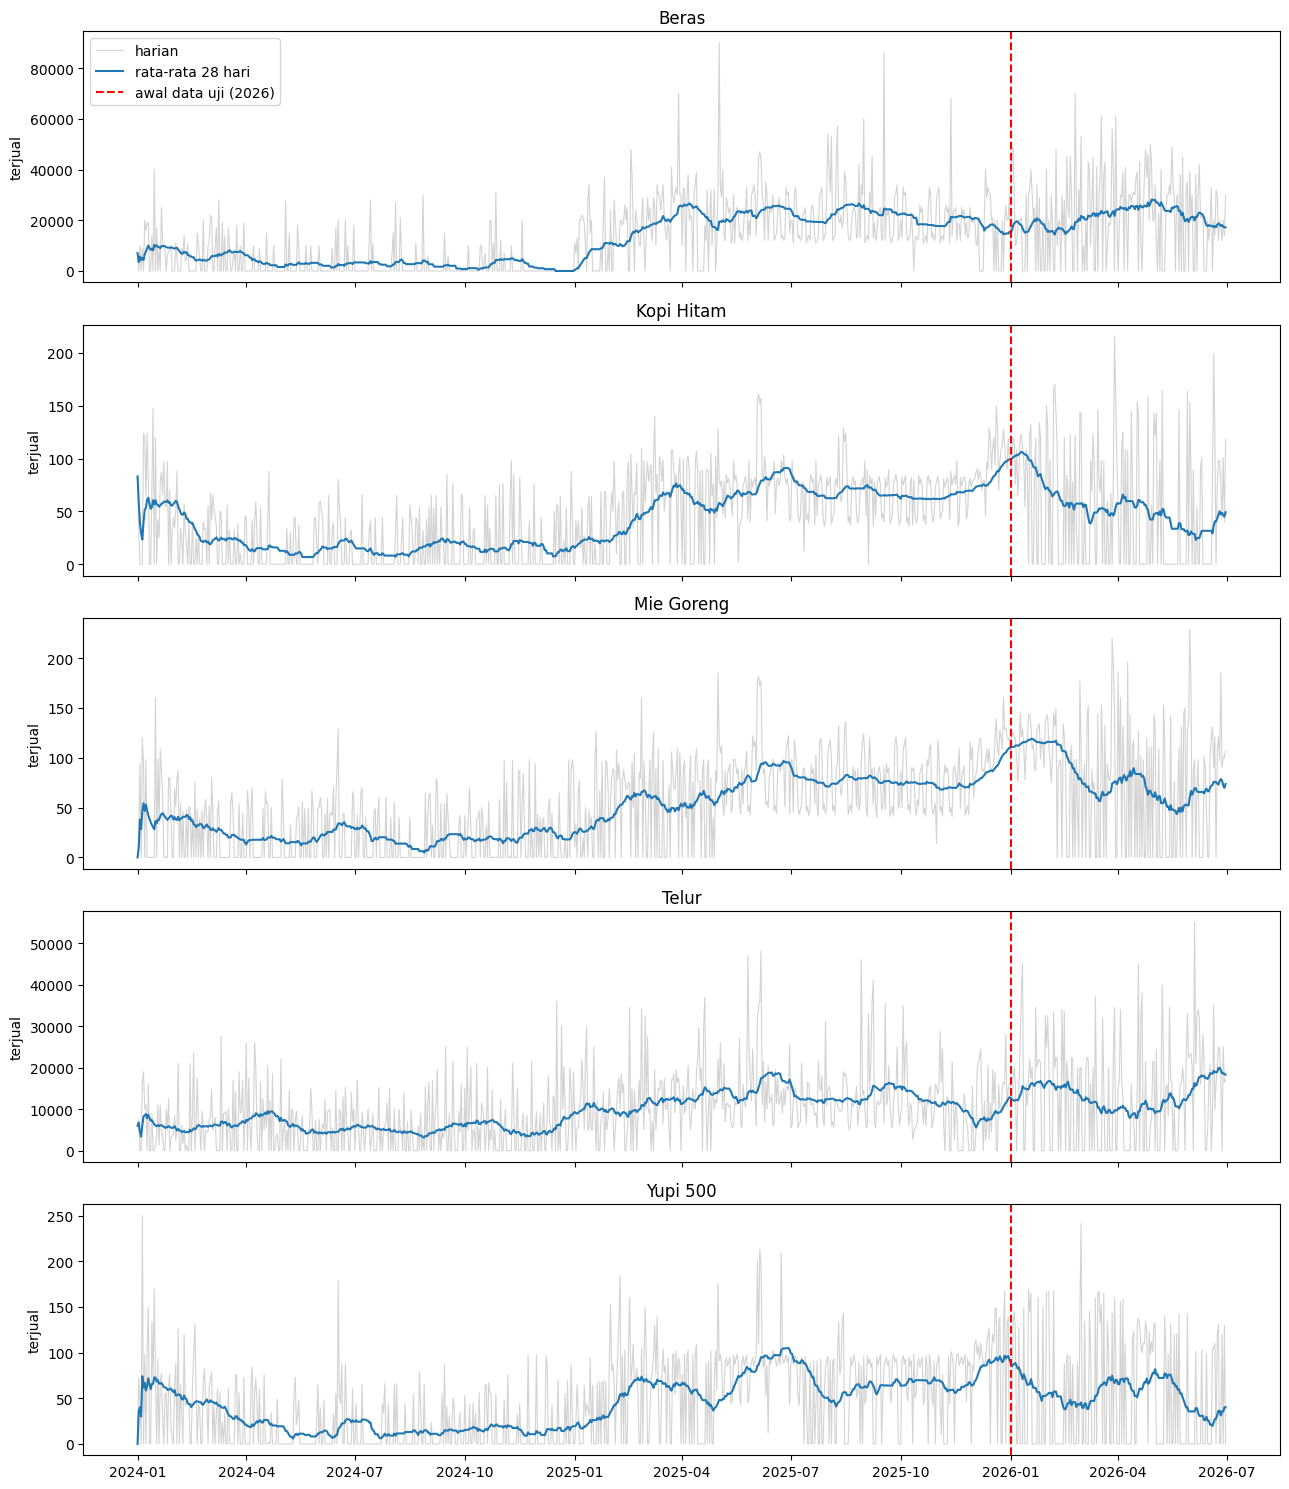

In [5]:
fig, axes = plt.subplots(len(PRODUCT_IDS), 1, figsize=(13, 3 * len(PRODUCT_IDS)), sharex=True)
for ax, pid in zip(axes, PRODUCT_IDS):
    g = df[df['product_id'] == pid].set_index('sale_date')['quantity_sold']
    ax.plot(g.index, g.values, color='lightgray', linewidth=0.8, label='harian')
    ax.plot(g.index, g.rolling(28, min_periods=1).mean(), color='tab:blue', linewidth=1.5, label='rata-rata 28 hari')
    ax.axvline(pd.Timestamp(TEST_START), color='red', linestyle='--', label='awal data uji (2026)')
    ax.set_title(PRODUCTS[pid]); ax.set_ylabel('terjual')
axes[0].legend(loc='upper left')
plt.tight_layout(); plt.show()

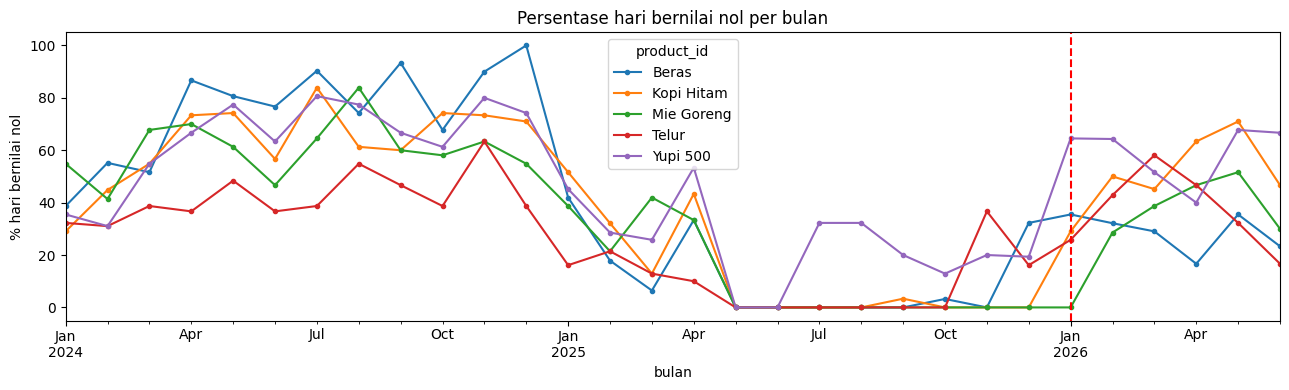

In [6]:
nol_bulanan = (df.assign(bulan=df['sale_date'].dt.to_period('M').dt.to_timestamp(), nol=(df['quantity_sold'] == 0))
                 .pivot_table(index='bulan', columns='product_id', values='nol', aggfunc='mean') * 100)
nol_bulanan = nol_bulanan.rename(columns=PRODUCTS)
nol_bulanan.plot(figsize=(13, 4), marker='o', markersize=3)
plt.axvline(pd.Timestamp(TEST_START), color='red', linestyle='--')
plt.ylabel('% hari bernilai nol'); plt.title('Persentase hari bernilai nol per bulan'); plt.tight_layout(); plt.show()

**Catatan data 2024:** banyak hari kosong yang pada pencatatan bernilai 0. Pemilik toko tidak dapat memastikan apakah itu memang tidak ada penjualan, data hilang, atau tidak tercatat, sehingga seluruhnya diperlakukan sebagai penjualan 0. Hal ini dicantumkan sebagai **batasan penelitian**.

## 3. Fungsi bantu dan ukuran error

| Ukuran | Cara membaca |
|---|---|
| MAE | rata-rata besar kesalahan dalam satuan asli (gram/pcs) |
| RMSE | besar kesalahan dalam satuan asli; lebih sensitif terhadap kesalahan besar |
| WAPE | total error absolut dibandingkan total aktual, dalam persen |
| sMAPE | error persentase simetris; 0% terbaik dan maksimum 200% |
| MAE relatif | MAE dibandingkan rata-rata aktual, untuk membantu membaca skala error |
| RMSE relatif | RMSE dibandingkan rata-rata aktual, untuk membantu membaca skala error |

**Catatan:** WAPE memiliki batas bawah 0%, tetapi tidak memiliki batas atas 100% secara umum. sMAPE yang digunakan di notebook memiliki rentang 0–200%.

Untuk pemilihan hyperparameter, **MAE cross-validation menjadi metrik utama**, sedangkan RMSE, sMAPE, dan WAPE menjadi metrik pendukung. Tidak digunakan batas universal "baik/sedang/buruk" tanpa dasar referensi; nilai error dibandingkan antar konfigurasi dan, pada hasil akhir, dapat dibaca relatif terhadap skala rata-rata data aktual.

Prediksi negatif dipotong menjadi 0 karena jumlah penjualan tidak mungkin negatif. Pembulatan untuk satuan pcs **tidak dilakukan di notebook ini**; pembulatan akan diterapkan pada implementasi aplikasi.


In [7]:
def prepare_prophet_data(product_df):
    x = product_df[['sale_date', 'quantity_sold']].rename(columns={'sale_date': 'ds', 'quantity_sold': 'y'})
    return x.sort_values('ds').reset_index(drop=True)


def calculate_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.clip(np.asarray(y_pred, dtype=float), 0, None)
    err = y_true - y_pred
    den = np.abs(y_true) + np.abs(y_pred)

    smape = np.mean(
        np.divide(2 * np.abs(err), den, out=np.zeros_like(den), where=den != 0)
    ) * 100

    total_actual = np.abs(y_true).sum()
    mean_actual = np.mean(y_true)

    return {
        'MAE': np.mean(np.abs(err)),
        'RMSE': np.sqrt(np.mean(err ** 2)),
        'WAPE_%': np.abs(err).sum() / total_actual * 100 if total_actual != 0 else np.nan,
        'sMAPE_%': smape,
        'MAE_relatif_%': np.mean(np.abs(err)) / mean_actual * 100 if mean_actual != 0 else np.nan,
        'RMSE_relatif_%': np.sqrt(np.mean(err ** 2)) / mean_actual * 100 if mean_actual != 0 else np.nan,
    }


def calculate_nonzero_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.clip(np.asarray(y_pred, dtype=float), 0, None)

    mask = y_true > 0
    if not mask.any():
        return {
            'jumlah_hari_nonzero': 0,
            'MAE_nonzero': np.nan,
            'RMSE_nonzero': np.nan,
            'WAPE_nonzero_%': np.nan,
            'sMAPE_nonzero_%': np.nan,
        }

    yt = y_true[mask]
    yp = y_pred[mask]
    err = yt - yp
    den = np.abs(yt) + np.abs(yp)
    smape = np.mean(
        np.divide(2 * np.abs(err), den, out=np.zeros_like(den), where=den != 0)
    ) * 100

    return {
        'jumlah_hari_nonzero': int(mask.sum()),
        'MAE_nonzero': np.mean(np.abs(err)),
        'RMSE_nonzero': np.sqrt(np.mean(err ** 2)),
        'WAPE_nonzero_%': np.abs(err).sum() / yt.sum() * 100,
        'sMAPE_nonzero_%': smape,
    }


# Cross-validation hanya memakai data latih 2024–2025. Alasan pemilihan angka dijelaskan di Bagian 5.
# initial : bekal data minimal sebelum "ujian" pertama (370 hari = lebih dari satu siklus tahunan penuh)
# horizon : berapa hari ke depan yang diramal dan dinilai pada tiap "ujian" (30 hari = prediksi maksimal di aplikasi)
# period  : jarak antar "ujian" (14 hari; lebih kecil dari horizon sehingga jendela ujian saling tumpang tindih)
CV_INITIAL = '370 days'
CV_PERIOD = '14 days'
CV_HORIZON = '30 days'


def run_cross_validation(model):
    try:
        return cross_validation(
            model,
            initial=CV_INITIAL,
            period=CV_PERIOD,
            horizon=CV_HORIZON,
            disable_tqdm=True
        )
    except TypeError:
        return cross_validation(
            model,
            initial=CV_INITIAL,
            period=CV_PERIOD,
            horizon=CV_HORIZON
        )


def cv_scores(df_cv):
    return calculate_metrics(df_cv['y'], df_cv['yhat'])


## 4. Holiday dan definisi model

Efek hari raya dihitung pada **jendela** di sekitar tanggal hari raya, yaitu sejumlah hari sebelum dan sesudahnya. Jendela ditetapkan sebagai asumsi penelitian berdasarkan analisis pola penjualan pada data latih 2024–2025. Jendela **tidak dituning** pada grid; kekuatan efek holiday dituning melalui `holidays_prior_scale`.

Untuk penelitian ini digunakan:
- **Idul Fitri: H-4 sampai H+3**
- **Idul Adha: H-2 sampai H+2**

Rentang ini memberi model kesempatan menangkap perubahan penjualan yang muncul beberapa hari sebelum maupun sesudah hari raya, tanpa memperlebar window secara berlebihan. Data 2026 tetap tidak digunakan untuk menentukan window.

Tanggal holiday tahun 2026 tetap dicantumkan karena digunakan saat prediksi final 2026.


In [8]:
# Jendela = (jumlah hari sebelum, jumlah hari sesudah) tanggal hari raya.
JENDELA_FITRI = (-4, 3)
JENDELA_ADHA = (-2, 2)

holidays = pd.concat([
    pd.DataFrame({
        'holiday': 'idul_fitri',
        'ds': pd.to_datetime(['2024-04-10', '2025-03-31', '2026-03-21']),
        'lower_window': JENDELA_FITRI[0],
        'upper_window': JENDELA_FITRI[1]
    }),
    pd.DataFrame({
        'holiday': 'idul_adha',
        'ds': pd.to_datetime(['2024-06-17', '2025-06-06', '2026-05-27']),
        'lower_window': JENDELA_ADHA[0],
        'upper_window': JENDELA_ADHA[1]
    }),
], ignore_index=True)
holidays

,holiday,ds,lower_window,upper_window
0,idul_fitri,2024-04-10,-4,3
1,idul_fitri,2025-03-31,-4,3
2,idul_fitri,2026-03-21,-4,3
3,idul_adha,2024-06-17,-2,2
4,idul_adha,2025-06-06,-2,2
5,idul_adha,2026-05-27,-2,2


### Pola penjualan di sekitar hari raya (data latih saja)

Tabel berikut membandingkan penjualan pada hari ke-k terhadap hari raya dengan penjualan hari biasa. Angka 1,0 berarti sama dengan kondisi normal; nilai di atas 1 menunjukkan penjualan lebih tinggi dan nilai di bawah 1 menunjukkan penjualan lebih rendah.

Analisis ini digunakan sebagai **dasar eksplorasi** untuk menentukan window, bukan sebagai proses tuning. Pola 2024 dan 2025 tidak selalu sama dan sebagian data 2024 bernilai 0, sehingga hasilnya tidak dianggap sebagai bukti bahwa setiap tahun akan mempunyai pola identik.


In [9]:
piv = train_df.pivot(index='sale_date', columns='product_id', values='quantity_sold')

def pola_sekitar(tanggal, offsets):
    d = pd.Timestamp(tanggal)
    dasar = piv.loc[[d + pd.Timedelta(days=k) for k in list(range(-28, -14)) + list(range(15, 29))]].mean()
    hasil = {}
    for k in offsets:
        rasio = (piv.loc[d + pd.Timedelta(days=k)] / dasar).replace([np.inf, -np.inf], np.nan)
        hasil[k] = np.nanmedian(rasio) if rasio.notna().any() else np.nan
    return pd.Series(hasil)

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    pola_fitri = pd.DataFrame({'Idul Fitri 2025': pola_sekitar('2025-03-31', range(-10, 7)),
                               'Idul Fitri 2024': pola_sekitar('2024-04-10', range(-10, 7))}).T
    pola_adha = pd.DataFrame({'Idul Adha 2025': pola_sekitar('2025-06-06', range(-5, 5)),
                              'Idul Adha 2024': pola_sekitar('2024-06-17', range(-5, 5))}).T
display(pola_fitri.round(2)); display(pola_adha.round(2))

,-10,-9,-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6
Idul Fitri 2025,1.07,0.0,1.67,1.67,1.44,1.23,1.76,1.6,1.34,1.60,0.84,0.53,1.53,1.71,0.0,1.55,1.58
Idul Fitri 2024,0.00,0.0,0.00,0.00,0.00,0.00,5.27,0.0,4.32,3.63,0.91,0.00,0.00,0.00,0.0,0.00,0.00


,-5,-4,-3,-2,-1,0,1,2,3,4
Idul Adha 2025,1.17,0.92,2.2,2.26,2.36,2.23,1.18,1.09,1.07,1.28
Idul Adha 2024,1.89,3.01,0.0,3.22,0.00,6.17,2.22,2.00,0.00,0.00


In [10]:
# Definisi model.
# Holiday selalu aktif.
# Empat hyperparameter berikut dituning secara bersamaan:
# CPS, SPS, seasonality_mode, dan HPS.
def make_model(cps=0.05, sps=10.0, mode='additive', hps=10.0):
    return Prophet(
        holidays=holidays,
        changepoint_prior_scale=cps,
        seasonality_prior_scale=sps,
        seasonality_mode=mode,
        holidays_prior_scale=hps
    )


# Model awal = parameter bawaan Prophet:
# cps=0.05, sps=10, additive, hps=10, dengan holiday aktif.
AWAL = {'cps': 0.05, 'sps': 10.0, 'mode': 'additive', 'hps': 10.0}


## 5. Model awal dan cross-validation

### Apa itu cross-validation? (penjelasan sederhana)

Bayangkan menilai seorang peramal cuaca. Menilainya dari **satu** ramalan saja kurang adil, bisa jadi ia kebetulan benar atau kebetulan salah. Cara yang lebih adil: minta ia meramal ke depan, cocokkan dengan kenyataan, lalu **ulangi pada banyak waktu yang berbeda**, dan ambil rata-rata kesalahannya.

Cross-validation pada deret waktu bekerja seperti itu:

1. Latih model dengan data sampai tanggal tertentu (disebut **cutoff**).
2. Minta model meramal 30 hari berikutnya, lalu bandingkan dengan penjualan yang sebenarnya.
3. Geser cutoff 14 hari ke depan, latih ulang, ramal lagi.
4. Ulangi sampai data latih habis, lalu hitung rata-rata kesalahan dari semua "ujian kecil" itu.

Hasilnya dipakai untuk **memilih parameter** tanpa menyentuh data uji 2026. Urutan waktu selalu dijaga: model tidak pernah melihat data yang berada setelah cutoff.

### Tiga pengaturan dan alasan pemilihannya

| Pengaturan | Arti sederhana | Nilai | Alasan |
|---|---|---|---|
| `initial` | bekal belajar minimal sebelum ujian pertama | 370 hari | Lebih dari satu tahun, sehingga model sempat melihat satu putaran musim penuh (yearly seasonality 365,25 hari) sebelum diuji |
| `horizon` | seberapa jauh ke depan diramal pada tiap ujian | 30 hari | Aplikasi menyediakan prediksi sampai maksimal 30 hari. Parameter dipilih dari ujian yang mencakup seluruh rentang prediksi yang bisa diminta pengguna |
| `period` | jarak antar ujian | 14 hari | Ujian dilakukan setiap 14 hari sehingga jumlahnya cukup banyak (24 ujian) dan seluruh hari 2025 beserta jendela hari raya ikut teruji |

**Jendela ujian saling tumpang tindih.** Karena period (14 hari) lebih kecil dari horizon (30 hari), satu hari yang sama dapat diuji hingga 3 kali oleh ujian yang berbeda. Cara ini diperbolehkan dan lazim dipakai pada rolling-origin evaluation, tetapi ujian-ujian yang tumpang tindih saling berkorelasi sehingga jumlah ujian yang benar-benar independen lebih sedikit dari 24. Tabel di bawah menunjukkan cakupan pengaturan yang dipakai.

**Catatan penting:** pengaturan dipilih berdasarkan **tujuan penggunaan** (prediksi maksimal 30 hari di aplikasi), bukan berdasarkan angka error yang lebih kecil. Error pada horizon yang lebih pendek tampak lebih kecil karena yang diramal lebih dekat, sehingga angka error antar pengaturan CV tidak bisa dibandingkan. Pengaturan CV tidak memengaruhi lebar interval `yhat_lower` dan `yhat_upper`; interval tidak dievaluasi di notebook ini.

### Model awal

Model dengan parameter bawaan, dievaluasi dengan cross-validation pada data latih. Hasilnya menjadi pembanding untuk tuning.


In [11]:
from prophet.diagnostics import generate_cutoffs

def cakupan_cv(initial, period, horizon):
    ds = pd.DataFrame({'ds': pd.date_range(TRAIN_START, TRAIN_END)})
    cutoffs = generate_cutoffs(ds, pd.Timedelta(horizon), pd.Timedelta(initial), pd.Timedelta(period))
    jumlah_diuji = {}
    for c in cutoffs:
        for d in pd.date_range(c + pd.Timedelta(days=1), c + pd.Timedelta(horizon)):
            jumlah_diuji[d] = jumlah_diuji.get(d, 0) + 1
    teruji = set(jumlah_diuji)
    # hari dalam jendela hari raya yang berada setelah cutoff pertama (hanya hari raya 2025 yang bisa diuji)
    awal_uji = min(cutoffs) + pd.Timedelta(days=1)
    jendela = set()
    for r in holidays.itertuples():
        for k in range(int(r.lower_window), int(r.upper_window) + 1):
            d = r.ds + pd.Timedelta(days=k)
            if awal_uji <= d <= pd.Timestamp(TRAIN_END):
                jendela.add(d)
    return {'period': period, 'horizon': horizon, 'jumlah_ujian': len(cutoffs),
            'hari_teruji': len(teruji), 'total_baris_dinilai': sum(jumlah_diuji.values()),
            'satu_hari_diuji_maks_berapa_kali': max(jumlah_diuji.values()),
            'hari_jendela_hari_raya_teruji': f'{len(jendela & teruji)} dari {len(jendela)}'}

pd.DataFrame([cakupan_cv(CV_INITIAL, CV_PERIOD, CV_HORIZON)])


,period,horizon,jumlah_ujian,hari_teruji,total_baris_dinilai,satu_hari_diuji_maks_berapa_kali,hari_jendela_hari_raya_teruji
0,14 days,30 days,24,352,720,3,13 dari 13


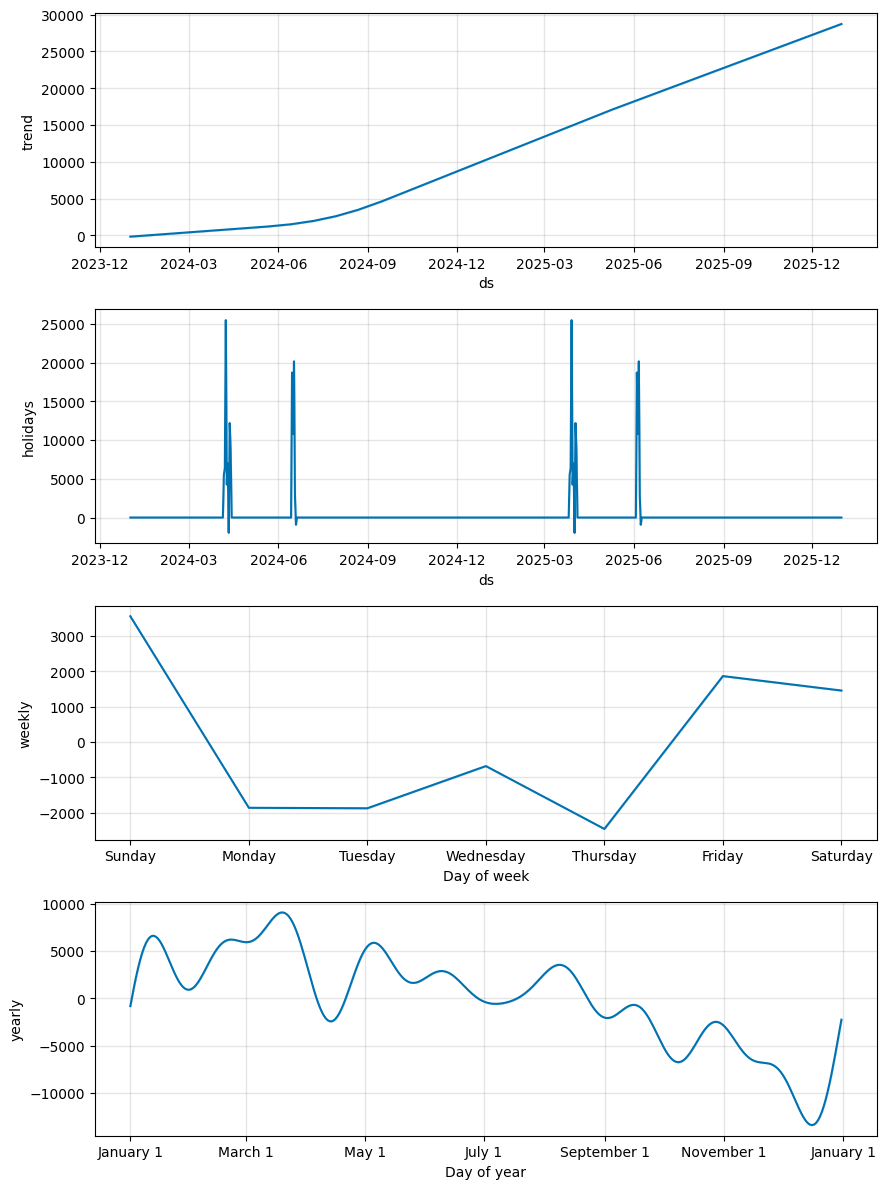

In [12]:
# Contoh komponen model awal (Beras): trend, holiday, weekly, yearly
x = prepare_prophet_data(train_df[train_df['product_id'] == 13])
m0 = make_model(**AWAL)
m0.fit(x)
m0.plot_components(m0.predict(x[['ds']]))
plt.show()

Komponen error ε(t) diasumsikan berdistribusi normal dengan rata-rata 0 dan sebaran σ. Nilai σ **diestimasi otomatis oleh Prophet saat model dilatih** (tidak diatur manual). Tabel berikut hanya untuk melihat hasil estimasinya, dalam satuan data (gram atau pcs). Sel ini opsional.

In [13]:
sigma_rows = []
for pid in PRODUCT_IDS:
    x = prepare_prophet_data(train_df[train_df['product_id'] == pid])
    m = make_model(**AWAL)
    m.fit(x)
    sigma_rows.append({'produk': PRODUCTS[pid], 'sigma_estimasi': float(np.mean(m.params['sigma_obs'])) * m.y_scale})
pd.DataFrame(sigma_rows).round(1)

,produk,sigma_estimasi
0,Beras,9387.5
1,Kopi Hitam,28.0
2,Mie Goreng,30.6
3,Telur,7168.0
4,Yupi 500,37.2


In [14]:
awal_rows = []
for pid in PRODUCT_IDS:
    x = prepare_prophet_data(train_df[train_df['product_id'] == pid])
    m = make_model(**AWAL)
    m.fit(x)
    cv = run_cross_validation(m)
    awal_rows.append({'produk': PRODUCTS[pid], 'jumlah_fold': cv['cutoff'].nunique(), **cv_scores(cv)})

awal_cv_df = pd.DataFrame(awal_rows)
print('Cutoff CV:', cv['cutoff'].min().date(), 's/d', cv['cutoff'].max().date())
awal_cv_df.round(2)

Cutoff CV: 2025-01-13 s/d 2025-12-01


,produk,jumlah_fold,MAE,RMSE,WAPE_%,sMAPE_%,MAE_relatif_%,RMSE_relatif_%
0,Beras,24,10319.86,13428.17,50.14,60.33,50.14,65.24
1,Kopi Hitam,24,30.77,40.19,46.49,69.02,46.49,60.73
2,Mie Goreng,24,31.90,38.86,43.31,60.25,43.31,52.77
3,Telur,24,6334.47,8795.72,50.89,56.64,50.89,70.67
4,Yupi 500,24,39.90,51.57,57.84,87.76,57.84,74.75


## 6. Tuning hyperparameter

Empat hyperparameter Prophet dituning **secara bersamaan dalam satu grid**. Kandidat nilai ditentukan oleh penelitian, kemudian setiap kombinasi dijalankan oleh Prophet dan dievaluasi dengan time-series cross-validation pada data 2024–2025.

| Parameter | Arti | Nilai yang dicoba |
|---|---|---|
| `changepoint_prior_scale` (CPS) | fleksibilitas trend terhadap perubahan | 0.01, 0.05, 0.1, 0.5 |
| `seasonality_prior_scale` (SPS) | fleksibilitas komponen musiman | 0.1, 1, 10 |
| `seasonality_mode` | bentuk efek musiman: `additive` atau `multiplicative` | additive, multiplicative |
| `holidays_prior_scale` (HPS) | fleksibilitas/kekuatan efek holiday | 0.1, 1, 10 |

Total = 4 × 3 × 2 × 3 = **72 kombinasi per produk** atau **360 kombinasi untuk 5 produk**.

Model awal Prophet (`CPS=0.05`, `SPS=10`, `mode=additive`, `HPS=10`) termasuk salah satu kandidat. Tidak digunakan aturan ambang perbaikan 5%; konfigurasi terbaik dipilih berdasarkan **MAE cross-validation terendah** pada masing-masing produk.


In [15]:
PARAM_GRID = {
    'cps': [0.01, 0.05, 0.1, 0.5],
    'sps': [0.1, 1.0, 10.0],
    'mode': ['additive', 'multiplicative'],
    'hps': [0.1, 1.0, 10.0],
}

configs = [dict(zip(PARAM_GRID, v)) for v in iter_product(*PARAM_GRID.values())]

assert AWAL in configs, 'Model awal harus menjadi salah satu kandidat'

print(
    'Kombinasi per produk:', len(configs),
    '| total CV run:', len(configs) * len(PRODUCT_IDS)
)


Kombinasi per produk: 72 | total CV run: 360


In [16]:
# Nama file memuat pengaturan CV agar hasil dari pengaturan CV yang berbeda tidak tercampur.
RESULT_FILE = f"hasil_tuning_cv_4param_h{CV_HORIZON.split()[0]}_p{CV_PERIOD.split()[0]}.csv"
rows = pd.read_csv(RESULT_FILE).to_dict('records') if os.path.exists(RESULT_FILE) else []

done = {
    (int(r['product_id']), float(r['cps']), float(r['sps']), str(r['mode']), float(r['hps']))
    for r in rows
}

start = time.time()

for pid in PRODUCT_IDS:
    x = prepare_prophet_data(train_df[train_df['product_id'] == pid])

    for cfg in configs:
        key = (pid, cfg['cps'], cfg['sps'], cfg['mode'], cfg['hps'])
        if key in done:
            continue

        m = make_model(**cfg)
        m.fit(x)

        rows.append({
            'product_id': pid,
            'produk': PRODUCTS[pid],
            **cfg,
            **cv_scores(run_cross_validation(m))
        })

        pd.DataFrame(rows).to_csv(RESULT_FILE, index=False)

    print(f'{PRODUCTS[pid]} selesai ({(time.time() - start) / 60:.1f} menit)')

tuning_df = pd.DataFrame(rows)
tuning_df.shape


Beras selesai (7.8 menit)
Kopi Hitam selesai (15.4 menit)


ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted


Mie Goreng selesai (22.8 menit)
Telur selesai (29.7 menit)


ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted


Yupi 500 selesai (37.5 menit)


(360, 12)

In [17]:
# Tambahan cek

# 1. Jumlah baris dan kombinasi unik
print("Jumlah baris:", len(tuning_df))
print("Kombinasi unik:", tuning_df[
    ["product_id", "cps", "sps", "mode", "hps"]
].drop_duplicates().shape[0])

# 2. Jumlah hasil per produk
print(tuning_df.groupby("produk").size())

# 3. Periksa metrik CV yang kosong atau tidak valid
# DIUBAH: Menggunakan nama kolom yang benar tanpa suffix '_CV'
metric_cols = ["MAE", "RMSE", "sMAPE_%", "WAPE_%"]

print(tuning_df[metric_cols].isna().sum())
print("MAE CV tidak finite:",
      (~np.isfinite(tuning_df["MAE"])).sum())

# 4. Periksa konfigurasi duplikat
print("Duplikat kombinasi:",
      tuning_df.duplicated(
          ["product_id", "cps", "sps", "mode", "hps"]
      ).sum())

Jumlah baris: 360
Kombinasi unik: 360
produk
Beras         72
Kopi Hitam    72
Mie Goreng    72
Telur         72
Yupi 500      72
dtype: int64
MAE        0
RMSE       0
sMAPE_%    0
WAPE_%     0
dtype: int64
MAE CV tidak finite: 0
Duplikat kombinasi: 0


### 6.1 Hasil tuning dan pemilihan kombinasi terbaik

In [18]:
# Seluruh kombinasi, diurutkan dari MAE terkecil per produk.
(tuning_df.sort_values(['product_id', 'MAE', 'RMSE'])
          [['produk', 'cps', 'sps', 'mode', 'hps', 'MAE', 'RMSE',
            'MAE_relatif_%', 'RMSE_relatif_%', 'WAPE_%', 'sMAPE_%']]
          .round(2)
          .reset_index(drop=True))


,produk,cps,sps,mode,hps,MAE,RMSE,MAE_relatif_%,RMSE_relatif_%,WAPE_%,sMAPE_%
0,Beras,0.01,0.1,additive,1.0,9739.15,13615.64,47.32,66.15,47.32,58.62
1,Beras,0.01,1.0,additive,1.0,9752.29,13693.88,47.38,66.53,47.38,56.88
2,Beras,0.01,1.0,additive,10.0,9769.83,13664.21,47.46,66.38,47.46,57.91
3,Beras,0.01,0.1,additive,10.0,9779.69,13687.14,47.51,66.50,47.51,58.93
4,Beras,0.01,10.0,additive,1.0,9789.34,13733.21,47.56,66.72,47.56,57.17
...,...,...,...,...,...,...,...,...,...,...,...
355,Yupi 500,0.01,10.0,multiplicative,1.0,48.93,56.34,70.92,81.66,70.92,112.04
356,Yupi 500,0.01,10.0,multiplicative,10.0,48.93,56.47,70.92,81.85,70.92,112.30
357,Yupi 500,0.01,10.0,multiplicative,0.1,49.33,56.79,71.50,82.32,71.50,112.52
358,Yupi 500,0.50,1.0,multiplicative,1.0,50.06,62.99,72.57,91.30,72.57,89.83


In [19]:
best_df = (
    tuning_df
    .sort_values(['product_id', 'MAE', 'RMSE'])
    .drop_duplicates('product_id')
    .set_index('product_id')
)

best_params = {
    pid: {
        'cps': float(best_df.loc[pid, 'cps']),
        'sps': float(best_df.loc[pid, 'sps']),
        'mode': str(best_df.loc[pid, 'mode']),
        'hps': float(best_df.loc[pid, 'hps'])
    }
    for pid in PRODUCT_IDS
}

# Pemeriksaan konsistensi: model awal di dalam grid harus sama dengan hasil Bagian 5.
awal_grid = tuning_df[
    (tuning_df['cps'] == AWAL['cps']) &
    (tuning_df['sps'] == AWAL['sps']) &
    (tuning_df['mode'] == AWAL['mode']) &
    (tuning_df['hps'] == AWAL['hps'])
].set_index('product_id')

selisih = awal_grid.loc[PRODUCT_IDS, 'MAE'].values - awal_cv_df['MAE'].values
assert np.abs(selisih).max() < 1e-6, 'Hasil model awal di grid berbeda dari Bagian 5'

hasil_cv = pd.DataFrame({
    'produk': [PRODUCTS[p] for p in PRODUCT_IDS],
    'cps_terpilih': [best_params[p]['cps'] for p in PRODUCT_IDS],
    'sps_terpilih': [best_params[p]['sps'] for p in PRODUCT_IDS],
    'mode_terpilih': [best_params[p]['mode'] for p in PRODUCT_IDS],
    'hps_terpilih': [best_params[p]['hps'] for p in PRODUCT_IDS],
    'MAE_CV_awal': [awal_grid.loc[p, 'MAE'] for p in PRODUCT_IDS],
    'MAE_CV_terpilih': [best_df.loc[p, 'MAE'] for p in PRODUCT_IDS],
    'RMSE_CV_terpilih': [best_df.loc[p, 'RMSE'] for p in PRODUCT_IDS],
    'sMAPE_CV_terpilih_%': [best_df.loc[p, 'sMAPE_%'] for p in PRODUCT_IDS],
    'WAPE_CV_terpilih_%': [best_df.loc[p, 'WAPE_%'] for p in PRODUCT_IDS],
})

hasil_cv['perbaikan_MAE_CV_%'] = (
    1 - hasil_cv['MAE_CV_terpilih'] / hasil_cv['MAE_CV_awal']
) * 100

display(hasil_cv.round(2))


,produk,cps_terpilih,sps_terpilih,mode_terpilih,hps_terpilih,MAE_CV_awal,MAE_CV_terpilih,RMSE_CV_terpilih,sMAPE_CV_terpilih_%,WAPE_CV_terpilih_%,perbaikan_MAE_CV_%
0,Beras,0.01,0.1,additive,1.0,10319.86,9739.15,13615.64,58.62,47.32,5.63
1,Kopi Hitam,0.50,0.1,additive,0.1,30.77,27.07,36.09,55.02,40.90,12.02
2,Mie Goreng,0.50,0.1,additive,1.0,31.90,30.28,36.84,54.89,41.11,5.08
3,Telur,0.01,1.0,multiplicative,10.0,6334.47,6196.03,8726.39,56.77,49.78,2.19
4,Yupi 500,0.05,0.1,multiplicative,1.0,39.90,38.20,48.86,80.76,55.37,4.27


### 6.1b Penetapan model akhir per produk

Konfigurasi model akhir dipilih langsung dari hasil full-grid tuning, yaitu kombinasi dengan **MAE cross-validation terendah** pada masing-masing produk.

Tidak digunakan ambang perbaikan 5% atau aturan threshold lain. Baseline tetap berada di dalam grid sehingga dapat dipilih kembali apabila memang menghasilkan MAE CV terendah.

Setelah konfigurasi dipilih, parameter dikunci. Data uji 2026 tidak digunakan untuk memilih atau mengubah konfigurasi.


In [20]:
# Model akhir = konfigurasi terbaik hasil CV.
final_params = {pid: dict(best_params[pid]) for pid in PRODUCT_IDS}

hasil_cv['model_akhir'] = 'tuning'
hasil_cv['model_akhir'] = hasil_cv['produk'].map(
    {PRODUCTS[p]: 'konfigurasi terbaik CV' for p in PRODUCT_IDS}
)

display(
    hasil_cv[
        ['produk', 'cps_terpilih', 'sps_terpilih', 'mode_terpilih',
         'hps_terpilih', 'MAE_CV_awal', 'MAE_CV_terpilih',
         'perbaikan_MAE_CV_%', 'model_akhir']
    ].round(2)
)


,produk,cps_terpilih,sps_terpilih,mode_terpilih,hps_terpilih,MAE_CV_awal,MAE_CV_terpilih,perbaikan_MAE_CV_%,model_akhir
0,Beras,0.01,0.1,additive,1.0,10319.86,9739.15,5.63,konfigurasi terbaik CV
1,Kopi Hitam,0.50,0.1,additive,0.1,30.77,27.07,12.02,konfigurasi terbaik CV
2,Mie Goreng,0.50,0.1,additive,1.0,31.90,30.28,5.08,konfigurasi terbaik CV
3,Telur,0.01,1.0,multiplicative,10.0,6334.47,6196.03,2.19,konfigurasi terbaik CV
4,Yupi 500,0.05,0.1,multiplicative,1.0,39.90,38.20,4.27,konfigurasi terbaik CV


### 6.2 Catatan HPS

`holidays_prior_scale` sudah dituning **bersamaan** dengan CPS, SPS, dan `seasonality_mode` pada full grid di Bagian 6. Karena itu tidak diperlukan tuning/sensitivity HPS tahap kedua.

HPS diperlakukan sebagai hyperparameter yang mengatur fleksibilitas efek holiday, sedangkan window holiday (`-4/+3` untuk Idul Fitri dan `-2/+2` untuk Idul Adha) tetap sebagai asumsi penelitian.


In [21]:
# Tampilkan konfigurasi terbaik per produk.
best_config_summary = best_df[
    ['produk', 'cps', 'sps', 'mode', 'hps',
     'MAE', 'RMSE', 'MAE_relatif_%', 'RMSE_relatif_%', 'WAPE_%', 'sMAPE_%']
].copy()

best_config_summary.round(2)


,produk,cps,sps,mode,hps,MAE,RMSE,MAE_relatif_%,RMSE_relatif_%,WAPE_%,sMAPE_%
product_id,,,,,,,,,,,
13,Beras,0.01,0.1,additive,1.0,9739.15,13615.64,47.32,66.15,47.32,58.62
129,Kopi Hitam,0.50,0.1,additive,0.1,27.07,36.09,40.90,54.53,40.90,55.02
158,Mie Goreng,0.50,0.1,additive,1.0,30.28,36.84,41.11,50.02,41.11,54.89
259,Telur,0.01,1.0,multiplicative,10.0,6196.03,8726.39,49.78,70.11,49.78,56.77
292,Yupi 500,0.05,0.1,multiplicative,1.0,38.20,48.86,55.37,70.82,55.37,80.76


In [22]:
class CatatPeringatan(logging.Handler):
    def __init__(self):
        super().__init__()
        self.jumlah = 0
    def emit(self, record):
        if 'Falling back to Newton' in record.getMessage():
            self.jumlah += 1

pelacak = CatatPeringatan()
logging.getLogger('prophet.models').addHandler(pelacak)

cek_rows = []
for pid in PRODUCT_IDS:
    x = prepare_prophet_data(train_df[train_df['product_id'] == pid])

    pelacak.jumlah = 0
    m = make_model(**final_params[pid])
    m.fit(x)
    n_fit_penuh = pelacak.jumlah

    pelacak.jumlah = 0
    mae_ulang = cv_scores(run_cross_validation(m))['MAE']
    n_cv = pelacak.jumlah

    cek_rows.append({
        'produk': PRODUCTS[pid],
        'fallback_saat_fit_penuh': n_fit_penuh,
        'fallback_saat_CV': n_cv,
        'MAE_CV_tuning': best_df.loc[pid, 'MAE'],
        'MAE_CV_ulang': mae_ulang,
        'selisih_%': (mae_ulang / best_df.loc[pid, 'MAE'] - 1) * 100,
    })

logging.getLogger('prophet.models').removeHandler(pelacak)
pd.DataFrame(cek_rows).round(3)

,produk,fallback_saat_fit_penuh,fallback_saat_CV,MAE_CV_tuning,MAE_CV_ulang,selisih_%
0,Beras,0,0,9739.146,9739.146,0.0
1,Kopi Hitam,0,0,27.069,27.069,0.0
2,Mie Goreng,0,0,30.282,30.282,0.0
3,Telur,0,0,6196.035,6196.035,0.0
4,Yupi 500,0,0,38.199,38.199,0.0


## 7. Uji final pada data 2026

Mulai dari bagian ini konfigurasi sudah **dikunci** berdasarkan CV pada data 2024–2025. Data 2026 tidak digunakan untuk tuning.

**Uji A (utama):** model final dilatih menggunakan seluruh data 2024–2025, kemudian memprediksi 181 hari Januari–Juni 2026 sekaligus tanpa pelatihan ulang. Hasil Uji A menjadi evaluasi utama generalisasi model.

**Uji B (tambahan, simulasi operasional):** walk-forward yang meniru cara kerja aplikasi. Di aplikasi ada penjadwalan (cron job) **setiap 1 minggu** yang memprediksi **2 minggu ke depan** dengan data terbaru. Pada notebook ini:

- `WF_STEP = 7`: model dilatih ulang setiap 7 hari (mingguan)
- `WF_HORIZON = 14`: setiap pelatihan ulang memprediksi 14 hari ke depan

Karena step (7) lebih kecil dari horizon (14), jendela prediksi saling tumpang tindih: satu hari diprediksi dua kali, sekali dari jarak 8–14 hari dan sekali dari jarak 1–7 hari. Uji B bukan dasar pemilihan hyperparameter dan hanya digunakan sebagai analisis tambahan.

Horizon CV (30 hari) lebih panjang daripada horizon Uji B (14 hari) karena CV mencakup seluruh rentang prediksi yang tersedia di aplikasi, sedangkan Uji B meniru penggunaan rutin (cron job mingguan).


In [23]:
test_dates = pd.DataFrame({'ds': pd.date_range(TEST_START, TEST_END)})

def forecast_181(pid, params):
    x = prepare_prophet_data(train_df[train_df['product_id'] == pid])
    m = make_model(**params)
    m.fit(x)
    return m.predict(test_dates)['yhat'].clip(lower=0).values


ujiA_rows = []
ujiA_nonzero_rows = []

for pid in PRODUCT_IDS:
    test_product = prepare_prophet_data(test_df[test_df['product_id'] == pid])
    y = test_product['y'].values

    pred = forecast_181(pid, final_params[pid])

    met = calculate_metrics(y, pred)
    nz = calculate_nonzero_metrics(y, pred)

    ujiA_rows.append({
        'produk': PRODUCTS[pid],
        **met
    })

    ujiA_nonzero_rows.append({
        'produk': PRODUCTS[pid],
        **nz
    })

ujiA_df = pd.DataFrame(ujiA_rows)
ujiA_nonzero_df = pd.DataFrame(ujiA_nonzero_rows)

print('Evaluasi utama — seluruh 181 hari:')
display(ujiA_df.round(2))

print('Evaluasi tambahan — hanya hari dengan aktual > 0:')
display(ujiA_nonzero_df.round(2))


Evaluasi utama — seluruh 181 hari:


,produk,MAE,RMSE,WAPE_%,sMAPE_%,MAE_relatif_%,RMSE_relatif_%
0,Beras,18531.40,22956.09,87.58,84.15,87.58,108.49
1,Kopi Hitam,83.06,99.17,157.06,116.64,157.06,187.53
2,Mie Goreng,61.93,81.83,78.73,80.62,78.73,104.03
3,Telur,11517.32,13996.62,84.99,94.77,84.99,103.29
4,Yupi 500,101.12,118.72,190.74,130.02,190.74,223.96


Evaluasi tambahan — hanya hari dengan aktual > 0:


,produk,jumlah_hari_nonzero,MAE_nonzero,RMSE_nonzero,WAPE_nonzero_%,sMAPE_nonzero_%
0,Beras,129,11161.53,13600.85,37.59,37.45
1,Kopi Hitam,89,33.17,42.87,30.84,30.46
2,Mie Goreng,122,27.81,36.27,23.83,22.88
3,Telur,114,6925.21,9098.41,32.19,32.92
4,Yupi 500,74,38.31,45.96,29.55,28.83


In [24]:
# WF_HORIZON: berapa hari ke depan diramal pada tiap pelatihan ulang
# WF_STEP   : seberapa sering model dilatih ulang (7 = mingguan, sesuai cron job aplikasi)
WF_HORIZON, WF_STEP = 14, 7
TEST_END_TS = pd.Timestamp(TEST_END)
origins = pd.date_range(TEST_START, TEST_END, freq=f'{WF_STEP}D')

def walk_forward(pid, predict_fn):
    full = prepare_prophet_data(df[df['product_id'] == pid])
    out = []

    for origin in origins:
        hist = full[full['ds'] < origin]
        target = full[
            (full['ds'] >= origin) &
            (full['ds'] < origin + pd.Timedelta(days=WF_HORIZON)) &
            (full['ds'] <= TEST_END_TS)
        ]

        if target.empty:
            continue

        out.append(
            target.assign(
                yhat=predict_fn(hist, target['ds']),
                jendela=origin
            )
        )

    return pd.concat(out, ignore_index=True)


def prophet_fn(params):
    def f(hist, dates):
        m = make_model(**params)
        m.fit(hist)
        return m.predict(pd.DataFrame({'ds': dates}))['yhat'].clip(lower=0).values
    return f


def rata2_28_fn(hist, dates):
    return np.repeat(hist['y'].iloc[-28:].mean(), len(dates))


ujiB_rows = []
wf_hasil = {}

for pid in PRODUCT_IDS:
    r = walk_forward(pid, prophet_fn(final_params[pid]))
    wf_hasil[pid] = r

    ujiB_rows.append({
        'produk': PRODUCTS[pid],
        **calculate_metrics(r['y'], r['yhat'])
    })

ujiB_df = pd.DataFrame(ujiB_rows)
ujiB_df.round(2)


,produk,MAE,RMSE,WAPE_%,sMAPE_%,MAE_relatif_%,RMSE_relatif_%
0,Beras,15826.14,19605.98,74.95,81.68,74.95,92.85
1,Kopi Hitam,53.55,61.34,102.92,132.21,102.92,117.90
2,Mie Goreng,49.09,60.69,62.89,89.95,62.89,77.75
3,Telur,10955.23,13154.61,80.78,97.74,80.78,97.00
4,Yupi 500,73.20,80.82,138.32,135.09,138.32,152.71


### Evaluasi total kebutuhan 14 hari

Untuk keputusan stok yang penting adalah **jumlah permintaan selama periode pemesanan**, bukan ketepatan tiap hari. Di sini prediksi dan penjualan aktual dijumlahkan per jendela 14 hari penuh, lalu dibandingkan. Karena pelatihan ulang dilakukan tiap 7 hari, jendela 14 hari yang berurutan saling tumpang tindih.

- **WAPE total** = jumlah |total aktual − total prediksi| ÷ jumlah total aktual × 100%
- **bias** = (total prediksi − total aktual) ÷ total aktual × 100%. Positif berarti prediksi **kelebihan** (risiko stok berlebih), negatif berarti **kekurangan** (risiko kehabisan stok)
- **dalam ±20%** = persentase jendela yang selisih totalnya tidak lebih dari 20%

In [25]:
tot_rows = []
for pid in PRODUCT_IDS:
    r = wf_hasil[pid]
    w = r.groupby('jendela').agg(aktual=('y', 'sum'), prediksi=('yhat', 'sum'), hari=('y', 'size'))
    w = w[w['hari'] == WF_HORIZON]          # hanya jendela 14 hari penuh
    e = w['prediksi'] - w['aktual']
    tot_rows.append({'produk': PRODUCTS[pid], 'model': 'final', 'jumlah_jendela': len(w),
                     'WAPE_total_%': np.abs(e).sum() / w['aktual'].sum() * 100,
                     'bias_%': e.sum() / w['aktual'].sum() * 100,
                     'dalam_20%_jendela': (np.abs(e) / w['aktual'] <= 0.2).mean() * 100})
total14_df = pd.DataFrame(tot_rows)
total14_df.round(1)

,produk,model,jumlah_jendela,WAPE_total_%,bias_%,dalam_20%_jendela
0,Beras,final,24,46.8,45.6,20.8
1,Kopi Hitam,final,24,37.9,23.9,37.5
2,Mie Goreng,final,24,27.1,14.7,29.2
3,Telur,final,24,38.5,30.9,37.5
4,Yupi 500,final,24,83.8,75.8,8.3


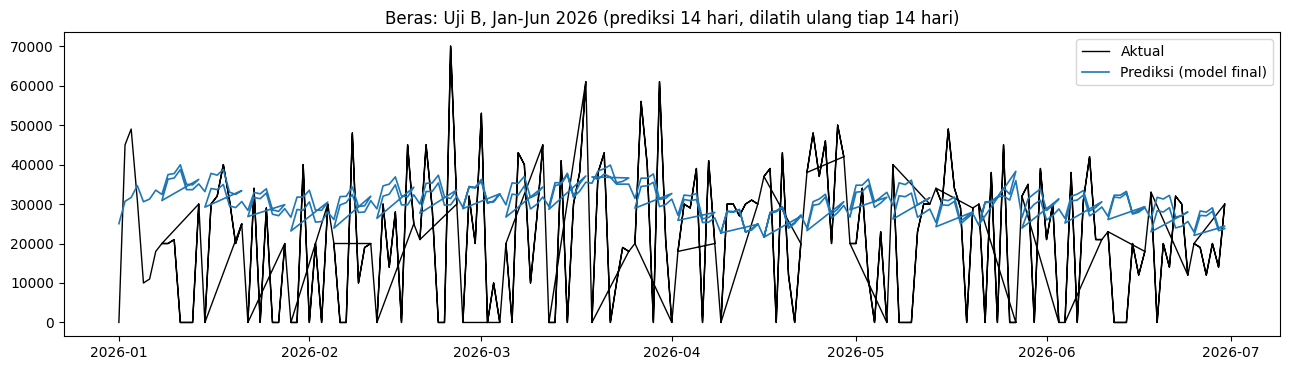

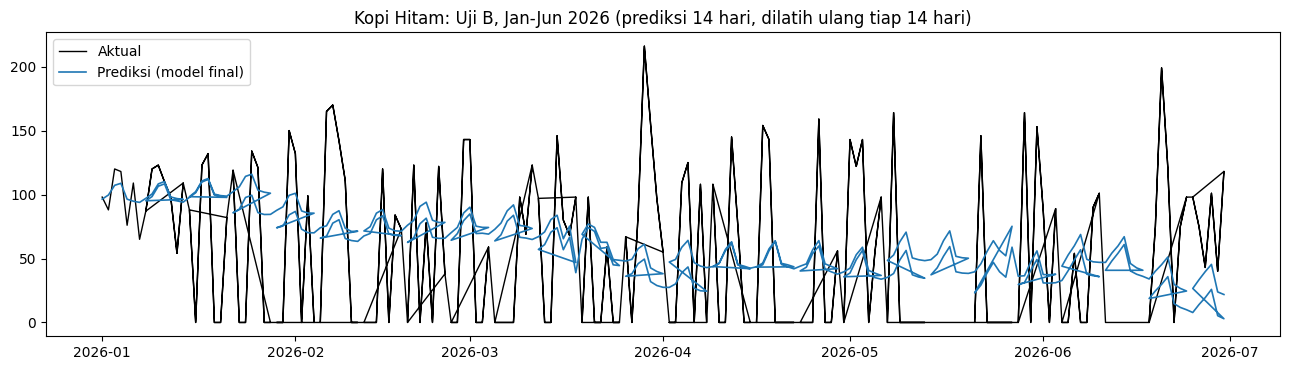

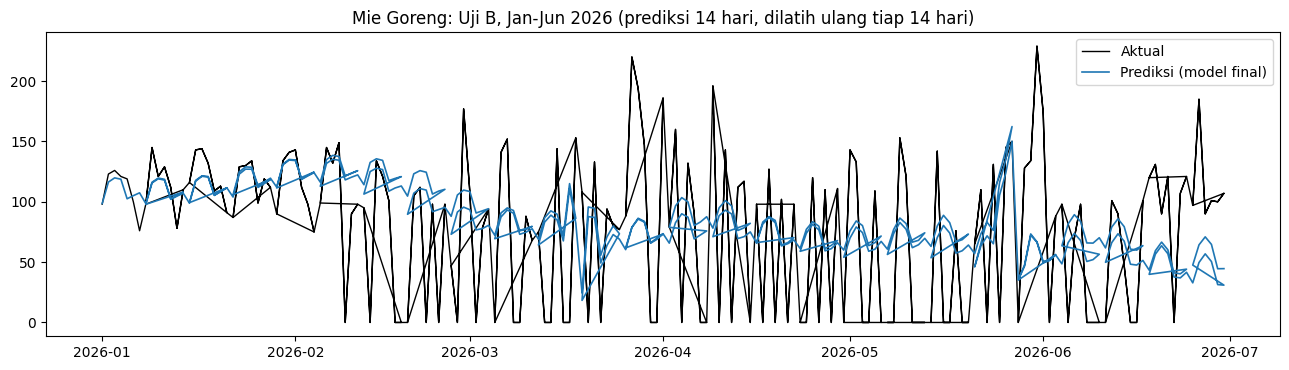

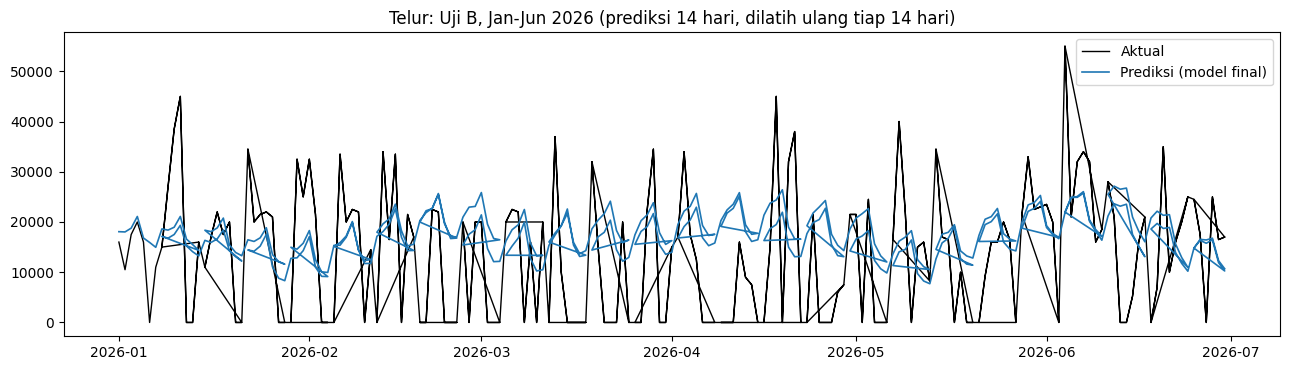

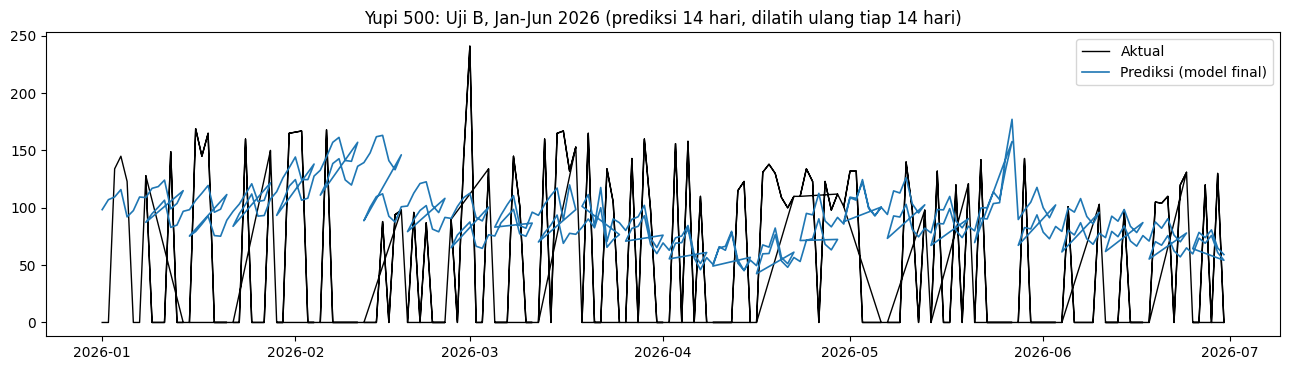

In [26]:
# Grafik Uji B: aktual vs prediksi model final
for pid in PRODUCT_IDS:
    r = wf_hasil[pid]
    plt.figure(figsize=(13, 3.8))
    plt.plot(r['ds'], r['y'], color='black', linewidth=1, label='Aktual')
    plt.plot(r['ds'], r['yhat'], color='tab:blue', linewidth=1.2, label='Prediksi (model final)')
    plt.title(f'{PRODUCTS[pid]}: Uji B, Jan-Jun 2026 (prediksi 14 hari, dilatih ulang tiap 14 hari)')
    plt.legend(); plt.tight_layout(); plt.show()

### Pembanding: model awal dan rata-rata 28 hari

Untuk menilai apakah tuning memang memperbaiki hasil, model final dibandingkan dengan **model awal** (parameter bawaan + holiday) dan dengan **rata-rata 28 hari terakhir** (metode sederhana tanpa Prophet) pada data uji yang sama. Pembanding ini hanya untuk membaca hasil dan **tidak dipakai untuk memilih model**. Sel ini opsional.

In [27]:
pemb_rows = []
for pid in PRODUCT_IDS:
    y181 = prepare_prophet_data(test_df[test_df['product_id'] == pid])['y'].values
    A_awal = calculate_metrics(y181, forecast_181(pid, AWAL))['MAE']
    A_final = calculate_metrics(y181, forecast_181(pid, final_params[pid]))['MAE']
    r_awal = walk_forward(pid, prophet_fn(AWAL))
    r_rata = walk_forward(pid, rata2_28_fn)
    B_awal = calculate_metrics(r_awal['y'], r_awal['yhat'])['MAE']
    B_final = calculate_metrics(wf_hasil[pid]['y'], wf_hasil[pid]['yhat'])['MAE']
    B_rata = calculate_metrics(r_rata['y'], r_rata['yhat'])['MAE']
    pemb_rows.append({'produk': PRODUCTS[pid],
                      'MAE_UjiA_awal': A_awal, 'MAE_UjiA_final': A_final,
                      'MAE_UjiB_awal': B_awal, 'MAE_UjiB_final': B_final, 'MAE_UjiB_rata2_28': B_rata})
pemb_df = pd.DataFrame(pemb_rows)
pemb_df.round(2)

,produk,MAE_UjiA_awal,MAE_UjiA_final,MAE_UjiB_awal,MAE_UjiB_final,MAE_UjiB_rata2_28
0,Beras,19145.84,18531.40,14913.87,15826.14,14127.16
1,Kopi Hitam,77.48,83.06,57.96,53.55,52.49
2,Mie Goreng,61.95,61.93,49.97,49.09,50.28
3,Telur,11108.50,11517.32,10849.03,10955.23,10676.61
4,Yupi 500,86.01,101.12,70.30,73.20,63.89


## 8. Reorder point (ROP) dan safety stock (SS)

### Gambaran sederhana

Toko memesan barang ketika stok tinggal sedikit. Pertanyaannya: **kapan** harus memesan? Barang baru datang beberapa hari setelah dipesan (lead time), dan selama menunggu barang tetap terjual. Maka batas pesan ulang (ROP) harus cukup untuk menutup kebutuhan selama menunggu, ditambah cadangan untuk berjaga-jaga bila penjualan lebih tinggi dari prediksi.

`ROP = D_L + tambahan`, dengan tambahan berupa cadangan (safety stock) yang disesuaikan dengan seberapa sering prediksi meleset.

| Istilah | Dibaca | Arti sederhana |
|---|---|---|
| lead time (L) | "led taim" | lama menunggu barang datang sejak dipesan: **3 hari** (di aplikasi diambil dari kolom supplier) |
| D_L | "di el" | jumlah prediksi penjualan selama lead time |
| safety stock (SS) | "sefti stok" | cadangan agar tidak kehabisan saat penjualan lebih tinggi dari prediksi |
| reorder point (ROP) | "riorder poin" | batas stok: jika stok ≤ ROP, saatnya memesan |
| service level | "sérvis level" | peluang stok cukup selama lead time. 95% berarti dari 20 kali pemesanan, sekitar 19 kali tidak kehabisan |
| error | | `aktual − prediksi`. **Negatif** = prediksi kelebihan, **positif** = prediksi kekurangan |
| bias | "baias" | rata-rata error: kecenderungan prediksi kelebihan (negatif) atau kekurangan (positif) |
| simpangan baku (σ) | "sigma" | seberapa tersebar error di sekitar rata-ratanya |
| kuantil / persentil | "kuantil" / "persentil" | nilai batas yang tidak dilewati sebagian data. Kuantil 95% = 95% data bernilai ≤ nilai itu |
| z | "zet" | pengali untuk service level: 1,28 (90%), 1,65 (95%), 2,33 (99%) |

### Apa itu kuantil (dengan contoh)

Bayangkan ada 100 kejadian pemesanan, lalu error-nya diurutkan dari yang paling kecil ke yang paling besar. **Kuantil 95% adalah error urutan ke-95**: 95 dari 100 kejadian punya error yang tidak lebih besar dari itu. Jika nilai itu ditambahkan ke prediksi, maka pada 95 dari 100 kejadian stok cukup. Itu sebabnya kuantil 95% cocok untuk service level 95%.

### Tiga aturan yang dibandingkan

| Aturan | Rumus | Catatan |
|---|---|---|
| A. rumus biasa | `ROP = D_L + z × σ` | rumus buku teks; **mengabaikan bias** |
| B. koreksi bias | `ROP = D_L + bias + z × σ` | memperhitungkan bias, mengandaikan error berdistribusi normal |
| C. kuantil empiris | `ROP = D_L + kuantil_p(error)` | langsung dari data; tidak mengandaikan distribusi normal dan bias ikut terhitung otomatis |

Aturan C disarankan karena data penjualan toko banyak bernilai nol sehingga sebaran errornya tidak normal.

### Bahan perhitungan

Bahan yang dipakai adalah hasil walk-forward (Uji B). Prediksi diperbarui tiap 7 hari, sehingga pemesanan bisa terjadi di hari mana pun dalam minggu itu. Maka dari setiap prediksi diambil 7 jendela selama 3 hari yang dimulai dari hari ke-1 sampai ke-7. Setiap jendela adalah **satu kejadian pemesanan**: jumlah prediksi dan jumlah penjualan nyata selama 3 hari tersebut.

**Catatan:** angka di bagian ini dikalibrasi pada data yang sama dengan evaluasinya, sehingga berfungsi sebagai contoh perhitungan. Di aplikasi, error dihitung ulang berkala dari riwayat prediksi dan penjualan nyata.

**Langkah 1: parameter dan penyusunan kejadian pemesanan.** Fungsi `jendela_lead_time` mengambil hasil walk-forward lalu, untuk setiap prediksi, memotong jendela 3 hari berturut-turut yang dimulai dari hari ke-1 sampai ke-7. Untuk tiap jendela dihitung jumlah penjualan nyata dan jumlah prediksi.

In [28]:
from scipy.stats import norm

LEAD_TIME_HARI = 3          # sama untuk semua produk; di aplikasi nilainya diambil dari kolom supplier
SERVICE_LEVEL = 0.95        # CONTOH: tentukan bersama pemilik toko dan pembimbing
UMUR_PREDIKSI_MAKS = 7      # prediksi diperbarui tiap 7 hari, jadi pemesanan bisa terjadi di hari ke-1 s.d. ke-7 sejak prediksi dibuat

z = norm.ppf(SERVICE_LEVEL)  # pengali z untuk service level (95% -> 1,645)
print(f'Lead time: {LEAD_TIME_HARI} hari | Service level: {SERVICE_LEVEL:.0%} | z = {z:.3f}')


def jendela_lead_time(pid):
    """Satu baris = satu 'kejadian pemesanan' selama lead time:
    jumlah penjualan nyata vs jumlah prediksi untuk LEAD_TIME_HARI hari berturut-turut,
    diambil dari hasil walk-forward (Uji B)."""
    hasil = []
    for asal, g in wf_hasil[pid].groupby('jendela'):
        g = g.sort_values('ds').reset_index(drop=True)
        for mulai in range(UMUR_PREDIKSI_MAKS):
            w = g.iloc[mulai:mulai + LEAD_TIME_HARI]
            if len(w) == LEAD_TIME_HARI:
                hasil.append({'asal_prediksi': asal, 'hari_mulai': mulai + 1,
                              'aktual': w['y'].sum(), 'prediksi': w['yhat'].sum()})
    return pd.DataFrame(hasil)


contoh = jendela_lead_time(PRODUCT_IDS[0])
print('Jumlah kejadian pemesanan (jendela lead time) per produk:', len(contoh))
contoh.head()

Lead time: 3 hari | Service level: 95% | z = 1.645
Jumlah kejadian pemesanan (jendela lead time) per produk: 179


,asal_prediksi,hari_mulai,aktual,prediksi
0,2026-01-01,1,94000.0,87386.467435
1,2026-01-01,2,125000.0,97026.619858
2,2026-01-01,3,90000.0,96906.742095
3,2026-01-01,4,52000.0,96500.316025
4,2026-01-01,5,39000.0,95362.788896


**Langkah 2: ukur seberapa meleset prediksinya.** Untuk setiap kejadian, error = aktual − prediksi. Dari kumpulan error itu dihitung rata-rata (bias), simpangan baku, dan kuantil sesuai service level. Bias negatif berarti prediksi cenderung kelebihan.

In [29]:
err_rows = []
for pid in PRODUCT_IDS:
    w = jendela_lead_time(pid)
    e = w['aktual'] - w['prediksi']          # negatif = prediksi kelebihan, positif = prediksi kekurangan
    err_rows.append({'produk': PRODUCTS[pid],
                     'jumlah_kejadian': len(w),
                     'rata2_aktual': w['aktual'].mean(),
                     'rata2_prediksi': w['prediksi'].mean(),
                     'bias (rata2 error)': e.mean(),
                     'simpangan_baku': e.std(),
                     f'kuantil_{SERVICE_LEVEL:.0%}': e.quantile(SERVICE_LEVEL)})
err_df = pd.DataFrame(err_rows)
err_df.round(1)

,produk,jumlah_kejadian,rata2_aktual,rata2_prediksi,bias (rata2 error),simpangan_baku,kuantil_95%
0,Beras,179,63525.1,90579.9,-27054.8,29629.6,27680.4
1,Kopi Hitam,179,157.3,179.8,-22.5,121.0,202.6
2,Mie Goreng,179,235.1,255.3,-20.2,108.4,190.0
3,Telur,179,40588.0,51291.5,-10703.5,24630.8,29189.2
4,Yupi 500,179,160.1,263.5,-103.4,142.0,149.2


**Langkah 3: bandingkan tiga aturan ROP.** Untuk tiap aturan dihitung `tambahan_ke_D_L` (angka yang ditambahkan ke prediksi kebutuhan lead time). Setiap aturan lalu diuji pada kejadian yang sama:

- `stok_cukup_%`: persentase kejadian pemesanan di mana penjualan nyata selama lead time tidak melebihi ROP
- `rata2_stok_berlebih`: rata-rata selisih ROP dikurangi penjualan nyata, saat ROP lebih besar dari penjualan nyata (semakin kecil, semakin hemat stok)

Cara membaca: aturan yang baik mencapai service level yang dituju dengan stok berlebih sekecil mungkin. Jika `stok_cukup_%` jauh di atas service level, ROP-nya terlalu tinggi sehingga stok menumpuk.

In [30]:
aturan_rows = []
for pid in PRODUCT_IDS:
    w = jendela_lead_time(pid)
    e = w['aktual'] - w['prediksi']
    # "tambahan" = berapa unit yang ditambahkan ke prediksi kebutuhan lead time (D_L) untuk mendapat ROP
    tambahan = {
        'A. rumus biasa (abaikan bias)':    z * e.std(),
        'B. koreksi bias + safety stock':   e.mean() + z * e.std(),
        'C. kuantil empiris':               e.quantile(SERVICE_LEVEL),
    }
    for nama, t in tambahan.items():
        rop = (w['prediksi'] + t).clip(lower=0)             # ROP tidak boleh negatif
        aturan_rows.append({
            'produk': PRODUCTS[pid], 'aturan': nama,
            'tambahan_ke_D_L': t,
            'ROP_rata2': rop.mean(),
            'stok_cukup_%': (w['aktual'] <= rop).mean() * 100,          # % kejadian pemesanan tanpa kehabisan
            'rata2_stok_berlebih': (rop - w['aktual']).clip(lower=0).mean(),
        })
aturan_df = pd.DataFrame(aturan_rows)
aturan_df.round(1)

,produk,aturan,tambahan_ke_D_L,ROP_rata2,stok_cukup_%,rata2_stok_berlebih
0,Beras,A. rumus biasa (abaikan bias),48736.3,139316.2,100.0,75791.0
1,Beras,B. koreksi bias + safety stock,21681.5,112261.4,92.7,49309.2
2,Beras,C. kuantil empiris,27680.4,118260.3,95.0,54924.3
3,Kopi Hitam,A. rumus biasa (abaikan bias),199.1,378.9,93.9,225.3
4,Kopi Hitam,B. koreksi bias + safety stock,176.6,356.4,93.3,204.3
5,Kopi Hitam,C. kuantil empiris,202.6,382.5,95.0,228.6
6,Mie Goreng,A. rumus biasa (abaikan bias),178.3,433.7,93.9,202.9
7,Mie Goreng,B. koreksi bias + safety stock,158.1,413.4,92.2,184.2
8,Mie Goreng,C. kuantil empiris,190.0,445.4,95.0,214.0
9,Telur,A. rumus biasa (abaikan bias),40514.1,91805.6,98.9,51313.7


**Langkah 4: gambar sebaran error.** Garis hitam adalah error 0, garis merah putus-putus adalah bias, dan garis hijau putus-putus adalah kuantil yang menjadi tambahan pada aturan C. Jika sebagian besar batang berada di kiri garis hitam, prediksi cenderung kelebihan.

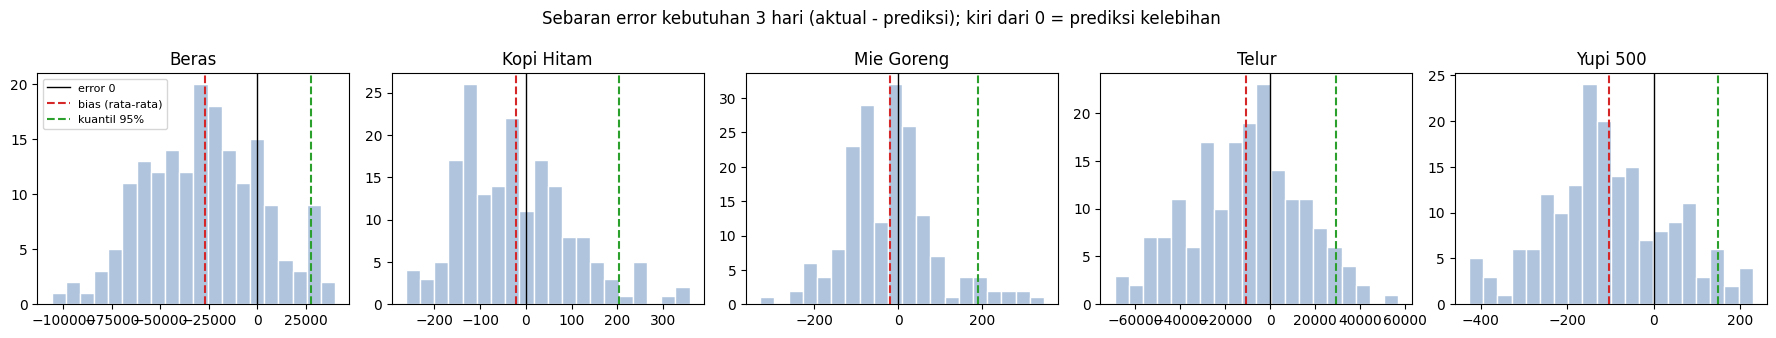

In [31]:
fig, axes = plt.subplots(1, len(PRODUCT_IDS), figsize=(18, 3.4))
for ax, pid in zip(axes, PRODUCT_IDS):
    w = jendela_lead_time(pid)
    e = w['aktual'] - w['prediksi']
    ax.hist(e, bins=20, color='lightsteelblue', edgecolor='white')
    ax.axvline(0, color='black', linewidth=1, label='error 0')
    ax.axvline(e.mean(), color='tab:red', linestyle='--', label='bias (rata-rata)')
    ax.axvline(e.quantile(SERVICE_LEVEL), color='tab:green', linestyle='--', label=f'kuantil {SERVICE_LEVEL:.0%}')
    ax.set_title(PRODUCTS[pid])
axes[0].legend(fontsize=8)
fig.suptitle(f'Sebaran error kebutuhan {LEAD_TIME_HARI} hari (aktual - prediksi); kiri dari 0 = prediksi kelebihan')
plt.tight_layout(); plt.show()

**Langkah 5: spesifikasi untuk backend.** Backend menghitung ROP dengan rumus sederhana: jumlah prediksi selama lead time ditambah nilai `tambahan` per produk (hasil Langkah 3), dipotong di nol. Tiga contoh berikut dipakai sebagai uji bersama: hasilnya harus sama di Python dan di Go.

Nilai `tambahan` bergantung pada lead time dan service level, sehingga dihitung ulang berkala di backend dari riwayat prediksi dan penjualan nyata, dan juga jika lead time di kolom supplier diubah.

In [32]:
def hitung_rop(prediksi_harian, tambahan):
    """Spesifikasi untuk backend: ROP = jumlah prediksi selama lead time + tambahan (tidak boleh negatif)."""
    d_l = sum(prediksi_harian)
    return max(0.0, d_l + tambahan)

# Contoh uji bersama (hasilnya harus sama di Python dan di Go):
print(hitung_rop([100, 120, 110], tambahan=40))     # 370.0
print(hitung_rop([100, 120, 110], tambahan=-40))    # 290.0
print(hitung_rop([10, 10, 10], tambahan=-100))      # 0.0 (dipotong di nol)

370
290
0.0


## 9. Menyimpan hasil dan konfigurasi untuk aplikasi

Bagian ini hanya **menyimpan hasil** dan tidak ada analisis baru: tabel ringkasan, konfigurasi model, serta tabel error dan ROP/SS dari Bagian 8.

`model_config.json` berisi daftar hari libur dan parameter **model final** per produk hasil full-grid tuning. Pembulatan hasil prediksi untuk satuan pcs **tidak dilakukan di notebook**; pembulatan akan diterapkan pada kode aplikasi.


In [33]:
def ambil(tabel, kolom):
    return tabel.set_index('produk')[kolom]


ringkasan = pd.DataFrame({
    'cps': [final_params[p]['cps'] for p in PRODUCT_IDS],
    'sps': [final_params[p]['sps'] for p in PRODUCT_IDS],
    'mode': [final_params[p]['mode'] for p in PRODUCT_IDS],
    'hps': [final_params[p]['hps'] for p in PRODUCT_IDS],
    'MAE_CV': hasil_cv['MAE_CV_terpilih'].values,
    'RMSE_CV': hasil_cv['RMSE_CV_terpilih'].values,
    'sMAPE_CV_%': hasil_cv['sMAPE_CV_terpilih_%'].values,
    'WAPE_CV_%': hasil_cv['WAPE_CV_terpilih_%'].values,
    'perbaikan_MAE_CV_%': hasil_cv['perbaikan_MAE_CV_%'].values,
    'MAE_UjiA': ujiA_df['MAE'].values,
    'RMSE_UjiA': ujiA_df['RMSE'].values,
    'MAE_relatif_UjiA_%': ujiA_df['MAE_relatif_%'].values,
    'RMSE_relatif_UjiA_%': ujiA_df['RMSE_relatif_%'].values,
    'sMAPE_UjiA_%': ujiA_df['sMAPE_%'].values,
    'WAPE_UjiA_%': ujiA_df['WAPE_%'].values,
    'hari_nonzero_UjiA': ujiA_nonzero_df['jumlah_hari_nonzero'].values,
    'MAE_nonzero_UjiA': ujiA_nonzero_df['MAE_nonzero'].values,
    'RMSE_nonzero_UjiA': ujiA_nonzero_df['RMSE_nonzero'].values,
    'sMAPE_nonzero_UjiA_%': ujiA_nonzero_df['sMAPE_nonzero_%'].values,
    'WAPE_nonzero_UjiA_%': ujiA_nonzero_df['WAPE_nonzero_%'].values,
    'MAE_UjiB': ujiB_df['MAE'].values,
    'RMSE_UjiB': ujiB_df['RMSE'].values,
    'sMAPE_UjiB_%': ujiB_df['sMAPE_%'].values,
    'WAPE_UjiB_%': ujiB_df['WAPE_%'].values,
}, index=list(PRODUCTS.values()))

ringkasan.to_csv('ringkasan_hasil_prophet.csv')
err_df.to_csv('error_lead_time.csv', index=False)      # dari Bagian 8
aturan_df.to_csv('hasil_rop_ss.csv', index=False)      # dari Bagian 8

model_config = {
    'defaults': {
        'cps': 0.05,
        'sps': 10.0,
        'mode': 'additive',
        'hps': 10.0
    },
    'holidays': [
        {
            'holiday': r.holiday,
            'ds': r.ds.strftime('%Y-%m-%d'),
            'lower_window': int(r.lower_window),
            'upper_window': int(r.upper_window)
        }
        for r in holidays.itertuples()
    ],
    'products': {
        str(pid): {
            'name': PRODUCTS[pid],
            'cps': final_params[pid]['cps'],
            'sps': final_params[pid]['sps'],
            'mode': final_params[pid]['mode'],
            'hps': final_params[pid]['hps']
        }
        for pid in PRODUCT_IDS
    },
}

with open('model_config.json', 'w', encoding='utf-8') as f:
    json.dump(model_config, f, indent=2, ensure_ascii=False)

ringkasan.round(2)

# Di Colab, unduh hasil (hapus '#'):
# from google.colab import files
# for f in ['model_config.json', 'ringkasan_hasil_prophet.csv', 'error_lead_time.csv', 'hasil_rop_ss.csv', RESULT_FILE]:
#     files.download(f)


,cps,sps,mode,hps,MAE_CV,RMSE_CV,sMAPE_CV_%,WAPE_CV_%,perbaikan_MAE_CV_%,MAE_UjiA,RMSE_UjiA,MAE_relatif_UjiA_%,RMSE_relatif_UjiA_%,sMAPE_UjiA_%,WAPE_UjiA_%,hari_nonzero_UjiA,MAE_nonzero_UjiA,RMSE_nonzero_UjiA,sMAPE_nonzero_UjiA_%,WAPE_nonzero_UjiA_%,MAE_UjiB,RMSE_UjiB,sMAPE_UjiB_%,WAPE_UjiB_%
Beras,0.01,0.1,additive,1.0,9739.15,13615.64,58.62,47.32,5.63,18531.40,22956.09,87.58,108.49,84.15,87.58,129,11161.53,13600.85,37.45,37.59,15826.14,19605.98,81.68,74.95
Kopi Hitam,0.50,0.1,additive,0.1,27.07,36.09,55.02,40.90,12.02,83.06,99.17,157.06,187.53,116.64,157.06,89,33.17,42.87,30.46,30.84,53.55,61.34,132.21,102.92
Mie Goreng,0.50,0.1,additive,1.0,30.28,36.84,54.89,41.11,5.08,61.93,81.83,78.73,104.03,80.62,78.73,122,27.81,36.27,22.88,23.83,49.09,60.69,89.95,62.89
Telur,0.01,1.0,multiplicative,10.0,6196.03,8726.39,56.77,49.78,2.19,11517.32,13996.62,84.99,103.29,94.77,84.99,114,6925.21,9098.41,32.92,32.19,10955.23,13154.61,97.74,80.78
Yupi 500,0.05,0.1,multiplicative,1.0,38.20,48.86,80.76,55.37,4.27,101.12,118.72,190.74,223.96,130.02,190.74,74,38.31,45.96,28.83,29.55,73.20,80.82,135.09,138.32
